# 08 Panel models: what moves together across 54 countries and 20+ years?

**Questions and hypotheses** (each tested within countries over time, with country and year effects)

| # | Model | Hypothesis |
|---|---|---|
| H1 | ln CO2 per capita on ln GDP per capita (and its square) | Income goes with higher emissions per person; the square tests for an inverted U (environmental Kuznets curve) |
| H2 | ln CO2 intensity on renewable electricity share | A higher renewable share goes with lower carbon intensity |
| H3 | Renewable electricity share on ln GDP per capita | Development goes with more renewable electricity |
| H4 | ln(1 + tree cover loss) on agricultural land share | More agricultural land goes with more tree cover loss |
| H5 | ND-GAIN exposure on ln GDP per capita (across countries) | Richer countries are less exposed (exposure has no income input) |

Controls: urbanisation, agriculture's share of GDP, natural resource rents, access to electricity, population growth, and governance. Governance is the first principal component of four World Governance Indicators. Income and governance are lagged one year.

**Method:** fixed effects with Driscoll-Kraay standard errors, which allow for heteroskedasticity, serial correlation and shocks shared across countries (droughts, commodity cycles). Random effects and pooled OLS are run for comparison, with a Hausman test between them. The Pesaran CD test checks whether shocks are shared across countries, and CIPS unit-root tests (with critical values simulated for this panel's size) check whether the series trend. Results are conditional associations, not causal effects.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "08 panel models"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

In [2]:
from linearmodels.panel import BetweenOLS, PanelOLS, PooledOLS, RandomEffects
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 1. Build the model variables

In [3]:
p = afp.copy()
for c in ("A01", "G02", "X01"):
    if c in p:
        p[f"ln_{c}"] = np.log(p[c].where(p[c] > 0))
if "ln_G02" in p:
    CENTRE = p["ln_G02"].mean()
    p["ln_G02_sq"] = (p["ln_G02"] - CENTRE) ** 2          # centred so the square is not collinear with the level
if "C03" in p:
    p["ln1p_C03"] = np.log1p(p["C03"])

wgi = [c for c in ("G12", "G13", "G14", "G15") if c in p]
ok = p[wgi].notna().all(axis=1)
z = (p.loc[ok, wgi] - p.loc[ok, wgi].mean()) / p.loc[ok, wgi].std()
_, sv, vt = np.linalg.svd(z.to_numpy(), full_matrices=False)
pc1 = z.to_numpy() @ vt[0]
p.loc[ok, "gov_pc1"] = pc1 if np.corrcoef(pc1, z.mean(axis=1))[0, 1] > 0 else -pc1      # higher = better governance
print(f"Governance PC1 explains {sv[0]**2 / (sv**2).sum():.1%} of the variance of the four WGI estimates")

p = p.sort_values(["iso3", "year"])
for c in ("ln_G02", "ln_G02_sq", "gov_pc1"):
    if c in p:
        p[c] = p.groupby("iso3")[c].shift(1)                              # lagged one year
p = p[p["year"] >= 2000].set_index(["iso3", "year"])

MODELS = {
    "H1 income and CO2": ("ln_A01", ["ln_G02", "ln_G02_sq", "G07", "G11", "gov_pc1"]),
    "H2 renewables and intensity": ("ln_X01", ["B10E", "G07", "G08", "ln_G02", "gov_pc1"]),
    "H3 development and renewables": ("B10E", ["ln_G02", "G07", "G11", "gov_pc1"]),
    "H4 agriculture and tree loss": ("ln1p_C03", ["C07", "G08", "ln_G02", "G06", "gov_pc1"]),
    "H5 income and exposure": ("F04A", ["ln_G02", "G07", "gov_pc1"]),
}
MODELS = {k: v for k, v in MODELS.items() if {v[0], *v[1]} <= set(p.columns)}
for k, (y, x) in MODELS.items():
    d = p[[y] + x].dropna()
    print(f"{k:32s} n = {len(d):5d}, countries = {d.index.get_level_values(0).nunique()}, years {d.index.get_level_values(1).min()} to {d.index.get_level_values(1).max()}")

Governance PC1 explains 90.2% of the variance of the four WGI estimates
H1 income and CO2                n =  1013, countries = 52, years 2001 to 2021
H2 renewables and intensity      n =  1136, countries = 51, years 2001 to 2024
H3 development and renewables    n =  1013, countries = 52, years 2001 to 2021
H4 agriculture and tree loss     n =  1127, countries = 51, years 2001 to 2024
H5 income and exposure           n =  1183, countries = 52, years 2001 to 2024


**The panel has 51 to 52 countries and up to 1,183 observations per model.** Governance compresses well into one factor: the first principal component explains 90.2% of the four WGI estimates.

## 2. Descriptive statistics

In [4]:
vars_ = sorted({v for y, x in MODELS.values() for v in [y] + x})
desc = p[vars_].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc.insert(0, "label", [label(v.replace("ln_", "").replace("ln1p_", "").replace("_sq", "")) for v in desc.index])
desc

,label,count,mean,std,min,50%,max
B10E,Renewable share of electricity generation (% o...,"1,340.000",39.809,37.245,0.000,28.096,100.000
C07,Agricultural land share (% of land area),"1,326.000",46.083,23.080,2.652,47.139,92.951
F04A,ND-GAIN Exposure (score (index 0 to 100; compo...,"1,325.000",0.533,0.043,0.458,0.527,0.630
G06,Population growth (annual %),"1,403.000",2.331,1.058,-5.416,2.445,6.410
G07,Urban population share (% of total population),"1,404.000",43.000,18.101,8.044,41.199,92.088
G08,"Agriculture, forestry and fishing value added ...","1,304.000",19.090,12.437,0.893,18.482,79.042
G11,Total natural resources rents (% of GDP),"1,146.000",11.694,11.873,0.002,7.655,88.592
gov_pc1,gov_pc1,"1,285.000",0.016,1.890,-4.472,0.042,5.049
ln1p_C03,Tree cover loss (hectares),"1,345.000",7.115,4.176,0.000,8.168,14.200
ln_A01,CO2 emissions excluding LULUCF per capita (t C...,"1,325.000",-0.797,1.413,-3.719,-0.981,2.555


## 3. Correlations and collinearity

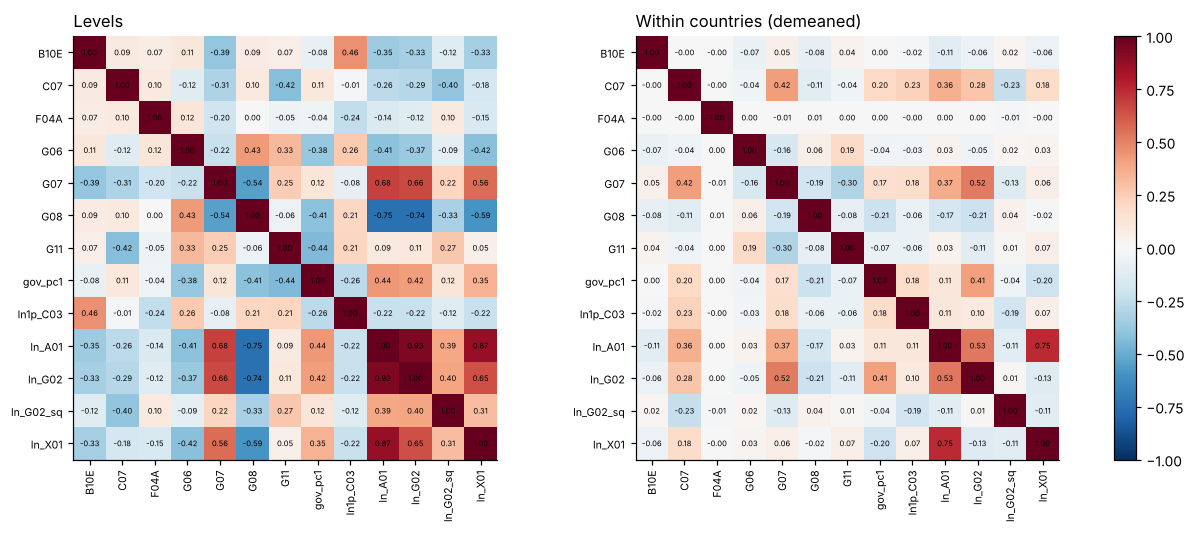

,H1 income and CO2,H2 renewables and intensity,H3 development and renewables,H4 agriculture and tree loss,H5 income and exposure
B10E,NaN,1.460,NaN,NaN,NaN
C07,NaN,NaN,NaN,1.230,NaN
G06,NaN,NaN,NaN,1.420,NaN
G07,2.150,2.320,2.080,NaN,1.910
G08,NaN,2.930,NaN,2.530,NaN
G11,1.630,NaN,1.480,NaN,NaN
gov_pc1,1.690,1.390,1.680,1.440,1.320
ln_G02,2.760,3.430,2.370,2.700,2.300
ln_G02_sq,1.410,NaN,NaN,NaN,NaN


In [5]:
within = p[vars_] - p[vars_].groupby(level=0).transform("mean")         # within-country variation, which is what FE uses
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (frame, title) in zip(ax, ((p[vars_], "Levels"), (within, "Within countries (demeaned)"))):
    r = frame.corr()
    im = a.imshow(r, cmap="RdBu_r", vmin=-1, vmax=1)
    a.set_xticks(range(len(vars_)), vars_, rotation=90, fontsize=7); a.set_yticks(range(len(vars_)), vars_, fontsize=7); a.grid(False)
    for i in range(len(vars_)):
        for j in range(len(vars_)):
            a.text(j, i, f"{r.iat[i, j]:.2f}", ha="center", va="center", fontsize=5)
    a.set_title(title, loc="left")
fig.colorbar(im, ax=ax, fraction=0.02); fig.savefig(OUT / "correlations.png", dpi=150, bbox_inches="tight"); plt.show()

vif = {}
for k, (y, x) in MODELS.items():
    X = p[x].dropna()
    X = (X - X.mean())
    vif[k] = pd.Series([variance_inflation_factor(X.values, i) for i in range(len(x))], index=x).round(2)
pd.DataFrame(vif)

**Collinearity is not a concern:** the highest VIF is 3.43 (income in H2).

## 4. Are shocks shared across countries? (Pesaran CD test)

In [6]:
def pesaran_cd(series):
    w = series.unstack(0)
    rho_sum, pairs = 0.0, 0
    cols = w.columns
    for a in range(len(cols)):
        for b in range(a + 1, len(cols)):
            ab = w[[cols[a], cols[b]]].dropna()
            if len(ab) >= 5 and ab.std().min() > 0:
                r = ab.corr().iat[0, 1]
                if np.isfinite(r):
                    rho_sum += np.sqrt(len(ab)) * r
                    pairs += 1
    cd = rho_sum / np.sqrt(pairs) if pairs else np.nan
    return cd, 2 * stats.norm.sf(abs(cd)), pairs

cd = pd.DataFrame([[v, *pesaran_cd(p[v].dropna())] for v in vars_], columns=["variable", "CD", "p", "pairs"]).set_index("variable")
cd

,CD,p,pairs
variable,,,
B10E,8.353,0.000,1225
C07,34.900,0.000,1376
F04A,NaN,NaN,0
G06,18.582,0.000,1431
G07,139.628,0.000,1431
G08,17.280,0.000,1372
G11,36.608,0.000,1428
gov_pc1,11.318,0.000,1431
ln1p_C03,22.861,0.000,1376


**Shocks are shared across countries for almost every variable,** so Driscoll-Kraay standard errors are the right default. CD statistics are significant at 1% for all variables except CO2 intensity.

## 5. Do the series trend? (CIPS unit-root test)

In [7]:
def cadf_t(y, ybar):
    dy, dyb = np.diff(y), np.diff(ybar)
    X = np.column_stack([np.ones(len(dy)), y[:-1], ybar[:-1], dyb])
    beta, *_ = np.linalg.lstsq(X, dy, rcond=None)
    e = dy - X @ beta
    s2 = e @ e / (len(dy) - X.shape[1])
    t = beta[1] / np.sqrt(s2 * np.linalg.pinv(X.T @ X)[1, 1])
    return t if np.isfinite(t) and abs(t) < 50 else np.nan             # drop numerically degenerate regressions


def cips(series, reps=300, seed=7):
    """CIPS on the balanced sub-panel of countries observed every year (no gaps filled).
    The 5% critical value is simulated for this N and T."""
    w = series.unstack(0).sort_index()
    w = w.loc[w.notna().any(axis=1)].dropna(axis=1)
    w = w.loc[:, (w.std() > 0) & (w.nunique() >= w.shape[0] // 2)]   # constant or mostly-repeated series cannot be tested
    if w.shape[0] < 15 or w.shape[1] < 5:
        return [np.nan, np.nan, w.shape[1], w.shape[0], "too few complete series"]
    Y = w.to_numpy()
    stat = np.nanmean([cadf_t(Y[:, i], Y.mean(axis=1)) for i in range(Y.shape[1])])
    rng = np.random.default_rng(seed)
    sims = []
    for _ in range(reps):
        S = np.cumsum(rng.standard_normal(Y.shape), axis=0)
        sims.append(np.nanmean([cadf_t(S[:, i], S.mean(axis=1)) for i in range(S.shape[1])]))
    cv = np.quantile(sims, 0.05)
    return [stat, cv, Y.shape[1], Y.shape[0], "stationary" if stat < cv else "unit root not rejected"]

ur = pd.DataFrame([[v, *cips(p[v].dropna())] for v in vars_ if v != "ln_G02_sq"],
                  columns=["variable", "CIPS", "5% critical", "N", "T", "result"]).set_index("variable")
ur

,CIPS,5% critical,N,T,result
variable,,,,,
B10E,-1.844,-2.444,7,26,unit root not rejected
C07,-1.770,-2.104,49,25,unit root not rejected
F04A,NaN,NaN,0,25,too few complete series
G06,-1.815,-2.134,53,26,unit root not rejected
G07,-1.660,-2.127,54,26,unit root not rejected
G08,-2.073,-2.104,45,26,unit root not rejected
G11,-2.230,-2.105,49,22,stationary
gov_pc1,-1.732,-2.064,52,24,unit root not rejected
ln1p_C03,-3.567,-2.094,46,25,stationary


**Most variables trend.** CO2 per capita, tree cover loss and resource rents reject a unit root. Income, renewables, urbanisation, governance and CO2 intensity do not. The fixed-effects results should therefore be read as associations in levels: country and year effects remove common trends but do not establish cointegration.

## 6. Estimate the models

In [8]:
def hausman(fe, re):
    common = [c for c in fe.params.index if c in re.params.index]
    b = fe.params[common] - re.params[common]
    v = fe.cov.loc[common, common] - re.cov.loc[common, common]
    stat = float(b @ np.linalg.pinv(v.to_numpy()) @ b)
    return stat, stats.chi2.sf(stat, len(common))


# ND-GAIN exposure is a projection that does not change within a country over time, so H5 cannot be
# estimated with country fixed effects. It is estimated across countries instead (between estimator:
# OLS on each country's average), with robust standard errors.
BETWEEN = {"H5 income and exposure"}
within_sd = p.groupby(level=0)["F04A"].std().median() if "F04A" in p else np.nan
print(f"Median within-country standard deviation of exposure: {within_sd:.6f} (zero means no change over time)")

coefs, diag, fe_res = [], [], {}
for k, (y, x) in MODELS.items():
    d = p[[y] + x].dropna()
    if k in BETWEEN:
        be = BetweenOLS(d[y], d[x].assign(const=1.0)).fit(cov_type="robust")
        fe_res[k] = be
        for v in be.params.index:
            coefs.append([k, "Between (robust)", v, be.params[v], be.std_errors[v], be.pvalues[v]])
        diag.append([k, y, len(d), d.index.get_level_values(0).nunique(), f"{d.index.get_level_values(1).min()} to {d.index.get_level_values(1).max()}",
                     be.rsquared, np.nan, np.nan, np.nan, np.nan])
        print(f"\n=== {k} (between countries) ===")
        print(be.summary.tables[1])
        continue
    fe = PanelOLS(d[y], d[x], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="kernel", kernel="bartlett")
    fe_cl = PanelOLS(d[y], d[x], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
    Xc = d[x].assign(const=1.0)
    re = RandomEffects(d[y], Xc).fit(cov_type="clustered", cluster_entity=True)
    po = PooledOLS(d[y], Xc).fit(cov_type="clustered", cluster_entity=True)
    h, hp = hausman(PanelOLS(d[y], d[x], entity_effects=True, drop_absorbed=True).fit(), RandomEffects(d[y], Xc).fit())
    cdr, cdp, _ = pesaran_cd(fe.resids)
    fe_res[k] = fe
    for est, r in (("FE Driscoll-Kraay", fe), ("FE clustered", fe_cl), ("RE clustered", re), ("Pooled clustered", po)):
        for v in r.params.index:
            coefs.append([k, est, v, r.params[v], r.std_errors[v], r.pvalues[v]])
    diag.append([k, y, len(d), d.index.get_level_values(0).nunique(), f"{d.index.get_level_values(1).min()} to {d.index.get_level_values(1).max()}",
                 fe.rsquared_within, h, hp, cdr, cdp])
    print(f"\n=== {k} ===")
    print(fe.summary.tables[1])

coefs = pd.DataFrame(coefs, columns=["model", "estimator", "variable", "coef", "std_err", "p"])
diag = pd.DataFrame(diag, columns=["model", "dependent", "obs", "countries", "years", "R2 (within; between for H5)", "Hausman", "Hausman_p", "CD_resid", "CD_p"]).set_index("model")
diag

Median within-country standard deviation of exposure: 0.000000 (zero means no change over time)



=== H1 income and CO2 ===
                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
ln_G02         0.6270     0.0823     7.6158     0.0000      0.4654      0.7885
ln_G02_sq     -0.1121     0.0171    -6.5597     0.0000     -0.1456     -0.0785
G07           -0.0007     0.0037    -0.1876     0.8512     -0.0079      0.0065
G11            0.0069     0.0014     5.0777     0.0000      0.0042      0.0095
gov_pc1       -0.0559     0.0192    -2.9030     0.0038     -0.0936     -0.0181



=== H2 renewables and intensity ===
                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
B10E          -0.0011     0.0010    -1.1258     0.2605     -0.0030      0.0008
G07            0.0046     0.0031     1.4879     0.1371     -0.0015      0.0107
G08            0.0003     0.0016     0.1999     0.8416     -0.0029      0.0035
ln_G02        -0.2936     0.0377    -7.7892     0.0000     -0.3676     -0.2196
gov_pc1       -0.0800     0.0153    -5.2247     0.0000     -0.1101     -0.0500



=== H3 development and renewables ===
                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
ln_G02        -10.451     2.3667    -4.4157     0.0000     -15.095     -5.8060
G07            0.4210     0.1641     2.5653     0.0105      0.0989      0.7430
G11            0.1005     0.0646     1.5557     0.1201     -0.0263      0.2272
gov_pc1        0.6049     0.9675     0.6252     0.5320     -1.2938      2.5037



=== H4 agriculture and tree loss ===
                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
C07            0.0556     0.0099     5.5933     0.0000      0.0361      0.0751
G08           -0.0016     0.0064    -0.2514     0.8015     -0.0141      0.0109
ln_G02        -0.5655     0.1700    -3.3257     0.0009     -0.8991     -0.2318
G06            0.0181     0.0406     0.4467     0.6552     -0.0615      0.0977
gov_pc1        0.2344     0.0454     5.1646     0.0000      0.1453      0.3234

=== H5 income and exposure (between countries) ===
                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
ln_G02         0.0025     0.0093     0.26

,dependent,obs,countries,years,R2 (within; between for H5),Hausman,Hausman_p,CD_resid,CD_p
model,,,,,,,,,
H1 income and CO2,ln_A01,1013,52,2001 to 2021,0.278,138.850,0.000,-2.007,0.045
H2 renewables and intensity,ln_X01,1136,51,2001 to 2024,0.035,72.537,0.000,-2.763,0.006
H3 development and renewables,B10E,1013,52,2001 to 2021,0.024,4.433,0.351,2.631,0.009
H4 agriculture and tree loss,ln1p_C03,1127,51,2001 to 2024,0.065,40.918,0.000,2.522,0.012
H5 income and exposure,F04A,1183,52,2001 to 2024,0.042,NaN,NaN,NaN,NaN


**Four models estimated within countries (fixed effects, Driscoll-Kraay), and H5 across countries:**

- **H1:** income has a significant positive link with CO2 per capita (0.627, p < 0.001), and the negative square (-0.112, p < 0.001) gives an inverted U.
- **H2:** the renewable electricity share has no significant link with CO2 intensity within countries (-0.001, p = 0.26). Income (-0.29) and governance (-0.08) are significant.
- **H3:** income has a significant **negative** link with the renewable share (-10.5, p < 0.001). Within countries, the renewable share of electricity falls as income rises.
- **H4:** agricultural land share has a significant positive link with tree cover loss (0.056, p < 0.001). Each extra point of agricultural land goes with about 5.7% more tree cover loss.
- **H5:** ND-GAIN exposure does not vary within countries (median within-country SD = 0), so it was estimated across countries. Income has no significant link with exposure (p = 0.79).

## 7. Compare estimators

In [9]:
wide = coefs.pivot_table(index=["model", "variable"], columns="estimator", values="coef").round(4)
wide

estimator                                Between (robust)  FE Driscoll-Kraay  \
model                         variable                                         
H1 income and CO2             G07                     NaN             -0.001   
                              G11                     NaN              0.007   
                              const                   NaN                NaN   
                              gov_pc1                 NaN             -0.056   
                              ln_G02                  NaN              0.627   
                              ln_G02_sq               NaN             -0.112   
H2 renewables and intensity   B10E                    NaN             -0.001   
                              G07                     NaN              0.005   
                              G08                     NaN              0.000   
                              const                   NaN                NaN   
                              gov_pc1                 NaN             -0.080   
                              ln_G02                  NaN             -0.294   
H3 development and renewables G07                     NaN              0.421   
                              G11                     NaN              0.101   
                              const                   NaN                NaN   
                              gov_pc1                 NaN              0.605   
                              ln_G02                  NaN            -10.451   
H4 agriculture and tree loss  C07                     NaN              0.056   
                              G06                     NaN              0.018   
                              G08                     NaN             -0.002   
                              const                   NaN                NaN   
                              gov_pc1                 NaN              0.234   
                              ln_G02                  NaN             -0.566   
H5 income and exposure        G07                  -0.001                NaN   
                              const                 0.536                NaN   
                              gov_pc1              -0.001                NaN   
                              ln_G02                0.003                NaN   

estimator                                FE clustered  Pooled clustered  \
model                         variable                                    
H1 income and CO2             G07              -0.001             0.012   
                              G11               0.007            -0.002   
                              const               NaN           -11.602   
                              gov_pc1          -0.056             0.075   
                              ln_G02            0.627             1.230   
                              ln_G02_sq        -0.112             0.056   
H2 renewables and intensity   B10E             -0.001            -0.003   
                              G07               0.005             0.008   
                              G08               0.000            -0.015   
                              const               NaN            -3.204   
                              gov_pc1          -0.080             0.036   
                              ln_G02           -0.294             0.124   
H3 development and renewables G07               0.421            -0.827   
                              G11               0.101             0.572   
                              const               NaN           106.931   
                              gov_pc1           0.605             0.082   
                              ln_G02          -10.451            -4.385   
H4 agriculture and tree loss  C07               0.056             0.021   
                              G06               0.018             0.701   
                              G08              -0.002            -0.007   
                             

**Hausman rejects random effects for H1, H2 and H4 (p < 0.001), so fixed effects is the right estimator there.** Pooled OLS gives different signs for several controls, a sign of omitted country effects.

## 8. Does it hold on a different sample?

Each model is re-run (FE, Driscoll-Kraay) without the four largest emitters (South Africa, Egypt, Algeria, Nigeria), on Sub-Saharan Africa only, and on 2010 onward.

In [10]:
samples = {"Full": lambda d: d,
           "Excl. ZAF, EGY, DZA, NGA": lambda d: d[~d.index.get_level_values(0).isin(["ZAF", "EGY", "DZA", "NGA"])],
           "Sub-Saharan only": lambda d: d[~d.index.get_level_values(0).isin(["DZA", "EGY", "LBY", "MAR", "TUN"])],
           "2010 onward": lambda d: d[d.index.get_level_values(1) >= 2010]}
rob = []
for k, (y, x) in MODELS.items():
    for s, f in samples.items():
        d = f(p[[y] + x].dropna())
        try:
            if k in BETWEEN:
                r = BetweenOLS(d[y], d[x].assign(const=1.0)).fit(cov_type="robust")
            else:
                r = PanelOLS(d[y], d[x], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="kernel", kernel="bartlett")
            main = x[0]
            rob.append([k, s, main, r.params.get(main, np.nan), r.pvalues.get(main, np.nan), len(d)])
        except Exception as e:
            rob.append([k, s, x[0], np.nan, np.nan, len(d)])
robust = pd.DataFrame(rob, columns=["model", "sample", "key variable", "coef", "p", "obs"])
robust.pivot_table(index=["model", "key variable"], columns="sample", values="coef").round(4)

,sample,2010 onward,"Excl. ZAF, EGY, DZA, NGA",Full,Sub-Saharan only
model,key variable,,,,
H1 income and CO2,ln_G02,0.593,0.649,0.627,0.642
H2 renewables and intensity,B10E,-0.006,-0.001,-0.001,-0.001
H3 development and renewables,ln_G02,-5.809,-10.099,-10.451,-11.886
H4 agriculture and tree loss,C07,0.031,0.055,0.056,0.057
H5 income and exposure,ln_G02,0.001,0.006,0.003,0.005


**Results hold across samples.**

- The income coefficient in H1 stays between 0.59 and 0.65 without the four largest emitters, in Sub-Saharan Africa only, and from 2010.
- H3 stays negative (-5.8 to -11.9). H4 stays positive (0.031 to 0.057).
- H2 is not significant in any sample.

## 9. Where the hypotheses land

In [11]:
expect = {"H1 income and CO2": ("ln_G02", "+"), "H2 renewables and intensity": ("B10E", "-"),
          "H3 development and renewables": ("ln_G02", "+"), "H4 agriculture and tree loss": ("C07", "+"),
          "H5 income and exposure": ("ln_G02", "-")}
rows = []
for k, (v, sign) in expect.items():
    if k not in fe_res:
        continue
    r = fe_res[k]
    b, pv = r.params[v], r.pvalues[v]
    ok_sign = (b > 0) == (sign == "+")
    verdict = "Supported" if pv < 0.05 and ok_sign else "Opposite sign, significant" if pv < 0.05 else "Not significant"
    rows.append([k, v, sign, b, pv, verdict])
if "H1 income and CO2" in fe_res:
    r = fe_res["H1 income and CO2"]
    rows.append(["H1 inverted U (EKC)", "ln_G02_sq", "-", r.params["ln_G02_sq"], r.pvalues["ln_G02_sq"],
                 "Supported" if r.pvalues["ln_G02_sq"] < 0.05 and r.params["ln_G02_sq"] < 0 else "Not supported"])
hyp = pd.DataFrame(rows, columns=["Hypothesis", "Variable", "Expected", "Coef", "p", "Verdict"])
hyp["Estimator"] = np.where(hyp["Hypothesis"].isin(BETWEEN), "Between, robust SE", "FE, Driscoll-Kraay SE")
if "H1 income and CO2" in fe_res:
    b1, b2 = fe_res["H1 income and CO2"].params["ln_G02"], fe_res["H1 income and CO2"].params["ln_G02_sq"]
    tp = np.exp(CENTRE - b1 / (2 * b2))
    gmax = np.exp(p["ln_G02"].max())
    print(f"EKC turning point: GDP per capita of about {tp:,.0f} (2021 PPP $); the highest in the African sample is {gmax:,.0f}. "
          f"{'Inside' if tp <= gmax else 'Outside'} the observed range.")
hyp

EKC turning point: GDP per capita of about 63,957 (2021 PPP $); the highest in the African sample is 39,995. Outside the observed range.


,Hypothesis,Variable,Expected,Coef,p,Verdict,Estimator
0,H1 income and CO2,ln_G02,+,0.627,0.000,Supported,"FE, Driscoll-Kraay SE"
1,H2 renewables and intensity,B10E,-,-0.001,0.261,Not significant,"FE, Driscoll-Kraay SE"
2,H3 development and renewables,ln_G02,+,-10.451,0.000,"Opposite sign, significant","FE, Driscoll-Kraay SE"
3,H4 agriculture and tree loss,C07,+,0.056,0.000,Supported,"FE, Driscoll-Kraay SE"
4,H5 income and exposure,ln_G02,-,0.002,0.790,Not significant,"Between, robust SE"
5,H1 inverted U (EKC),ln_G02_sq,-,-0.112,0.000,Supported,"FE, Driscoll-Kraay SE"


## 10. Save tables

In [12]:
save_excel("panel results.xlsx", {"Hypotheses": hyp.set_index("Hypothesis"), "Diagnostics": diag, "Coefficients": coefs.set_index("model"),
                                  "Estimator comparison": wide, "Robustness": robust.set_index("model"), "Descriptives": desc,
                                  "CD test": cd, "CIPS": ur, "VIF": pd.DataFrame(vif)})

['correlations.png', 'panel results.xlsx']

## What I found

| Hypothesis | Result | Verdict |
|---|---|---|
| H1 Income goes with higher CO2 per capita | 0.627, p < 0.001 | Supported |
| H1 Inverted U (EKC) | square -0.112, p < 0.001; turning point about 64,000 PPP $ | Supported in form, but outside Africa's range |
| H2 Renewables go with lower carbon intensity | -0.001, p = 0.26 | Not significant |
| H3 Development goes with more renewables | -10.45, p < 0.001 | Rejected: significant but opposite sign |
| H4 Agricultural land goes with tree cover loss | 0.056, p < 0.001 | Supported |
| H5 Income goes with lower exposure | 0.002, p = 0.79 | Not significant |

- **Africa is on the rising side of the curve.** The EKC turning point is about 64,000 PPP $ per person, above the richest African country in the sample (about 40,000). For every African economy, more income still means more CO2 per person.
- **Rising income goes with a falling renewable share of electricity** within countries (H3 rejected).
- **Agricultural expansion goes with forest loss**, robustly across samples.
- **Better governance goes with lower emissions and lower carbon intensity**, but with higher recorded tree cover loss. The data does not explain that last result, so it needs a closer look.

**Limits:** these are conditional associations. Several series trend, and cointegration is not tested, so the results do not establish causality.

**Why it matters for finance:** the H1 and H3 results mean African growth will raise emissions unless new generation is renewable. Development finance and project lenders funding power capacity are effectively choosing Africa's emissions path.